**This is a holiday themed data set on Turkey Prices, lets use it for some extra practice**

In [1]:
#first lets bring in our tools
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [5]:
#now lets read in the data and take a peek at it
df = pd.read_excel('Turkey_Price.xlsx')
df.head()

,Year,Month,Price
0,2010,February,1.375
1,2010,March,1.425
2,2010,April,1.479
3,2010,May,1.464
4,2010,June,1.474


In [6]:
#lets look for missing data
df.isna().sum()

Year     0
Month    0
Price    1
dtype: int64

In [10]:
#there is one missing data point, I think I want to fill that data point with an average price so we dont leave out a months observation
df1 =  df.fillna(df.mean(numeric_only = True)) #creates a new data frame named df1 and fills the missing value with a simple mean
df1.isna().sum() #double checks the new frame to make sure no missing values

Year     0
Month    0
Price    0
dtype: int64

In [71]:
#looks good, lets proceed. 
#lets look at average price per year and create a bar chart
yearlyprice = df1.groupby('Year')['Price'].mean() #groups by year with mean price
#lets make sure it worked
print(yearlyprice)

Year
2010    1.483818
2011    1.583667
2012    1.621667
2013    1.641562
2014    1.601250
2015    1.505417
2016    1.552667
2017    1.582083
2018    1.500750
2019    1.520000
2020    1.609500
Name: Price, dtype: float64


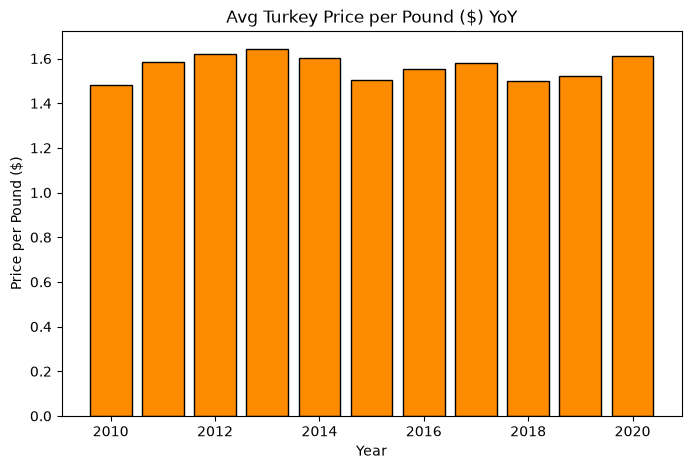

In [72]:
#now lets create a bar chart with matplotlib
plt.figure(figsize = (8,5)) #sets size
plt.bar(yearlyprice.index, yearlyprice.values, color = 'darkorange', edgecolor = 'black') #creates a bar chart as specified
plt.title("Avg Turkey Price per Pound ($) YoY") #titles
plt.xlabel("Year") #x label
plt.ylabel("Price per Pound ($)") #y label
plt.show() #displays

**From this we can see that the avg price was lowest in 2010 and highest in 2013 and 2020**

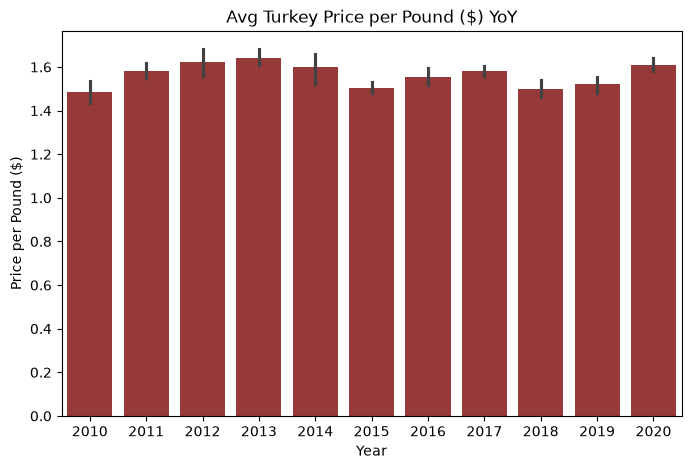

In [91]:
#for practice I will repeat the above chart with seaborn
plt.figure(figsize = (8,5)) #sets canvas size
sns.barplot(data = df1, x = 'Year', y = 'Price', color = 'brown') #creates the bar chart
plt.title("Avg Turkey Price per Pound ($) YoY") #titles
plt.xlabel("Year") #x label
plt.ylabel("Price per Pound ($)") #y label
plt.show() #displays

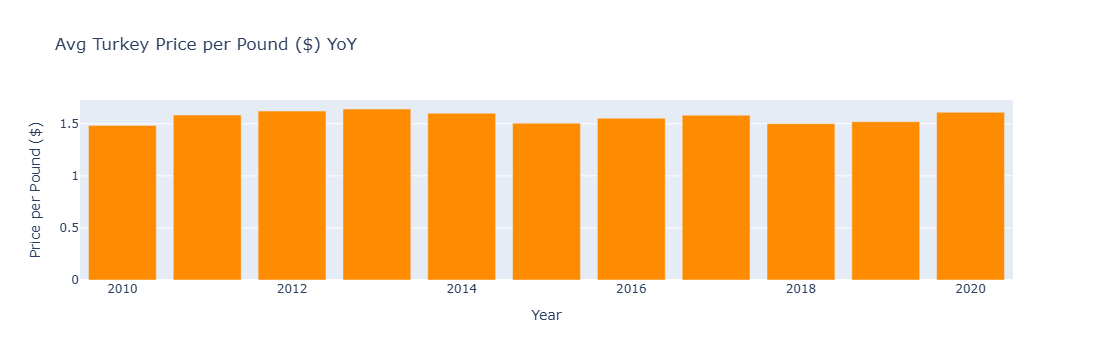

In [92]:
#and again with plotly
fig = px.bar( #creates the bar
    x = yearlyprice.index, #sets x
    y = yearlyprice.values, #sets y
    labels = {'x': 'Year', 'y': 'Price per Pound ($)'}, #labels both axis
    title = 'Avg Turkey Price per Pound ($) YoY', #titles the chart
    color_discrete_sequence = ['darkorange']) #tries for a festive color
fig.show() #displays


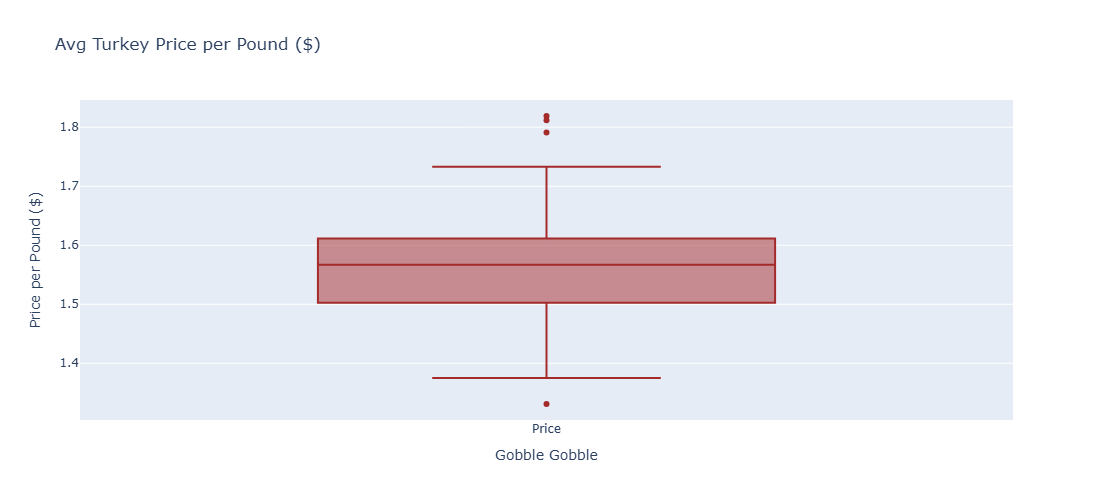

In [93]:
#Now I am curious about the spread of the data, to get a quick look at that I will use a boxplot using plotly
fig = px.box(df1, y = ['Price'], #creates the boxplot based on our data frame (df1) with the price variable
             title = "Avg Turkey Price per Pound ($)", #titles
             color_discrete_sequence = ['brown']) #attempts to use a brown color to keep things autumn and festive

fig.update_layout(
    xaxis_title = "Gobble Gobble", #turkey caption
    yaxis_title = "Price per Pound ($)", #y label
    width = 800, #size
    height = 500)

fig.show() #displays

**Based on the chart above, we have an outlier low price of 1.33 as well a few outlier highs of 1.819, 1.812, and 1.791**

In [94]:
#Next I want to look at average price per month. I will do a groupby month with mean price
monthlyprice = df1.groupby('Month')['Price'].mean() #groups by month wth mean price
print(monthlyprice)

Month
April        1.565900
August       1.592700
December     1.461500
February     1.542545
January      1.541000
July         1.587500
June         1.554800
March        1.576500
May          1.559600
November     1.490100
October      1.632774
September    1.625800
Name: Price, dtype: float64


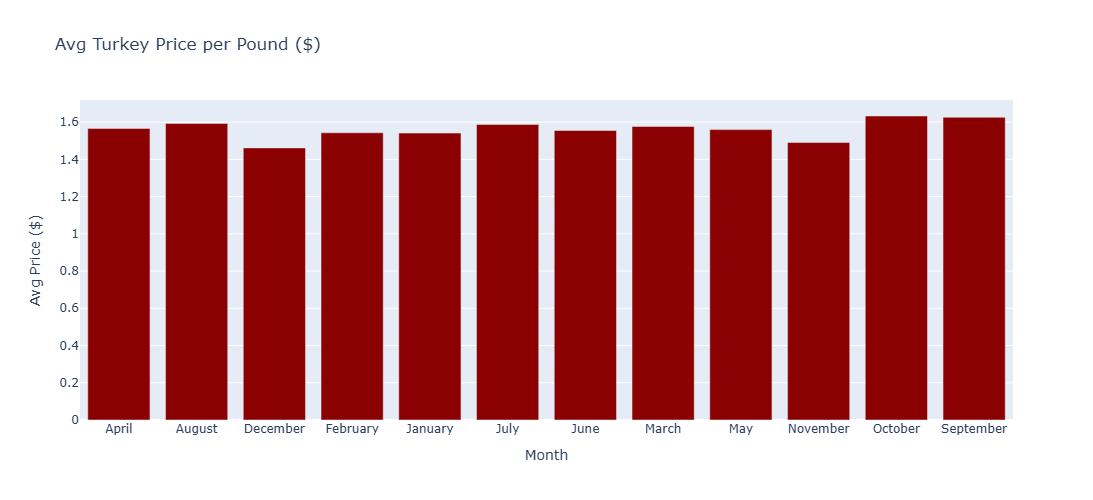

In [95]:
#Now lets chart it out and look to see what we can discover using plotly
fig = px.bar( #creates a bar chart in plotly
    x = monthlyprice.index, #with months on the x
    y = monthlyprice.values, #and avg price on the y
    labels = {'x': 'Month', 'y': 'Avg Price ($)'}, #labels both axis
    title = 'Avg Turkey Price per Pound ($)', #titles the chart
    color_discrete_sequence = ['darkred']) # again attempting for a festive color

fig.update_layout( #updates the chart for better size
    width = 800,
    height = 500)

fig.show() #displays

**Based on the chart above we can see that, on average, the most expensive month to buy a turkey is October at 1.63 per pound while December is the cheapest at 1.46**

In [88]:
#finally lets use a couple simple functions to some fun stats with the original data
print("The most expensive price per pound in the data set was\n",df1.max())

The most expensive price per pound in the data set was
 Year          2020
Month    September
Price        1.819
dtype: object


In [89]:
print("The cheapest price per pound in the data set was\n",df1.min(),'Year', 'Month', 'Price')

The cheapest price per pound in the data set was
 Year      2010
Month    April
Price    1.331
dtype: object Year Month Price
